### RL based Autonomous in Mobile Networks

[mobile-env](https://github.com/stefanbschneider/mobile-env/tree/main) allows modeling users moving around an area and can connect to one or multiple base stations. Environment supports multi-agent and centralized reinforcement learning policies.

Given a number of base stations or cells (BS) and user equipments (UEs), work with the objective to decide what connections should be established among UEs and BSs to maximize Quality of Experience (QoE) globally.

#### Mobile Networks

To maximize QoE of single UEs, the UE connects to as many BSs as possible, which yields higher macro data rates. However, BSs multiplex resources among connected URs and UEs compete for limited resources (conflicting goals). To achieve maximum QoE globally, the policy must consider two crucial factors.
- The data rate (DR in GB/s) of each connection is determined by the channel's quality between UE and BS (signal-to-noise-ratio).
- The QoE of individual UEs doesn't necessarily increase linearly with higher data rates.

In [ ]:
# Install mobile-env, gymnasium, stable_baselines3 and ray configuration dependencies cleanly
!pip install mobile-env > /dev/null 2>&1
!pip install "gymnasium<2.0,>=0.29.1" > /dev/null 2>&1
!pip install stable_baselines3==2.0.0 > /dev/null 2>&1
!pip install ray > /dev/null 2>&1

In [ ]:
# Cleanly ensure the requested compatible gymnasium library is installed
!pip install --force-reinstall --no-cache-dir gymnasium > /dev/null 2>&1

Make small/medium/large mobile environment for a single, centralized control agent. Pass rgb_array as render mode so the env can be rendered.

In [ ]:
import gymnasium
import matplotlib.pyplot as plt
import mobile_env

# Create a small mobile environment configured with centralized agent controls
# Use rgb_array render mode to allow rendering frames inline within Colab
env_mobile: gymnasium.Env = gymnasium.make("mobile-small-central-v0", render_mode="rgb_array")

# Retrieve and display core properties from the unwrapped environment
num_users: int = env_mobile.unwrapped.NUM_USERS
num_stations: int = env_mobile.unwrapped.NUM_STATIONS
print(f"\nSmall environment initialized with {num_users} users and {num_stations} cells.")


Small environment initialized with 5 users and 3 cells.


Run simulation for 10 time steps with random actions

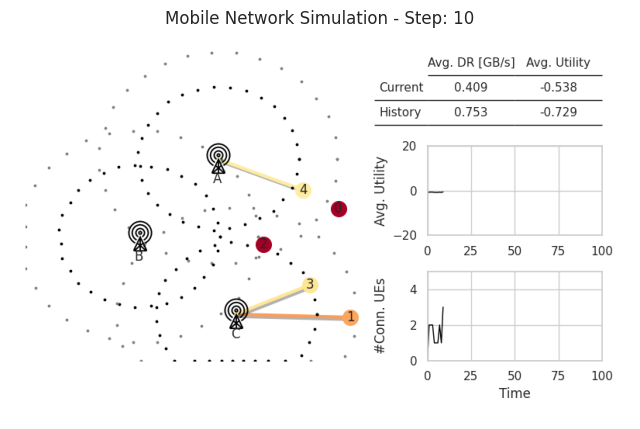

In [ ]:
from IPython import display
import numpy as np

# Run the mobile network simulation for 10 time steps with random behavior
done: bool = False
obs, info = env_mobile.reset()

for step_idx in range(10):
    # Sample a randomized coordination action from the action space
    dummy_action = env_mobile.action_space.sample()
    obs, reward, terminated, truncated, info = env_mobile.step(dummy_action)

    # Render the current state of the cell connections
    plt.figure(figsize=(8, 6), dpi=100)
    plt.imshow(env_mobile.render())
    plt.title(f"Mobile Network Simulation - Step: {step_idx + 1}", fontsize=12)
    plt.axis('off')

    display.display(plt.gcf())
    display.clear_output(wait=True)
    plt.close()

Centralized RL policy learning

The objective to train a single centralized PPO agent to learn optimal policy for mobile netowrk coordination.

In [ ]:
# Quietly install stable-baselines3 dependencies if required
!pip install stable_baselines3 > /dev/null 2>&1

In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.ppo import MlpPolicy

# Instantiate a stable-baselines3 centralized PPO agent
model_mobile_ppo: PPO = PPO(
    MlpPolicy,
    env_mobile,
    tensorboard_log='results_sb_mobile',
    verbose=1
)

# Train the centralized agent on the small mobile environment
model_mobile_ppo.learn(total_timesteps=10000, progress_bar=True)

Render environment state after training

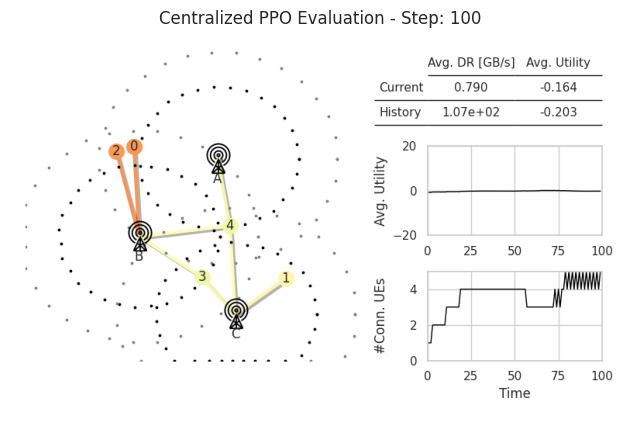

In [ ]:
from IPython import display
import matplotlib.pyplot as plt

# Evaluate the newly trained model over a complete episode run
obs, info = env_mobile.reset()
done: bool = False
step_count: int = 0

while not done:
    # Predict the next best coordination configuration
    action, _ = model_mobile_ppo.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env_mobile.step(action)
    done = terminated or truncated
    step_count += 1

    # Render and update the environment state visualization
    plt.figure(figsize=(8, 6), dpi=100)
    plt.imshow(env_mobile.render())
    plt.title(f"Centralized PPO Evaluation - Step: {step_count}", fontsize=12)
    plt.axis('off')

    display.display(plt.gcf())
    display.clear_output(wait=True)
    plt.close()

#### Observed features

Handlers define observation and action spaces as well as the reward in the environment. Designing an MDP for a reinforcement learning approach we quickly validate it by implementing a new handler in mobile-env.

Default Observation features
- The current connections between users and cells (binary)
- The signal-to-noise-ratio (SNR) between all users and cells (normalized to [0,1])
- The current utility (i.e QoE) of each user normalized to [-1,1]


In [ ]:
# List the station identifiers and user equipment identifiers in the environment
stations_list = list(env_mobile.unwrapped.stations)
users_list = list(env_mobile.unwrapped.users)
print("Stations:", stations_list)
print("Users:", users_list)

Stations: [0, 1, 2]
Users: [0, 1, 2, 3, 4]


In [ ]:
from typing import Dict, Any

# Inspect raw feature mapping from the unwrapped mobile environment
mobile_features: Dict[int, Any] = env_mobile.unwrapped.features()
mobile_features

In [ ]:
# Reset environment state with a fixed seed for reproducible observations
obs, info = env_mobile.reset(seed=42)
obs, reward, terminated, truncated, info = env_mobile.step(env_mobile.action_space.sample())

print(f"Raw Observations Vector shape: {obs.shape}")
print(f"Raw Observation Values: {obs}\n")

# Calculate observation slice size per user equipment
obs_per_usr: int = 2 * env_mobile.unwrapped.NUM_STATIONS + 1

# Map and print structured observations for each user
for ue_idx in range(env_mobile.unwrapped.NUM_USERS):
    print(f"\nObservations for user {ue_idx + 1}:")
    offset: int = ue_idx * obs_per_usr

    # Slice out connections, SNRs, and utility scores cleanly
    connections = obs[offset: offset + env_mobile.unwrapped.NUM_STATIONS]
    snrs = obs[offset + env_mobile.unwrapped.NUM_STATIONS: offset + 2 * env_mobile.unwrapped.NUM_STATIONS]
    utility = obs[offset + 2 * env_mobile.unwrapped.NUM_STATIONS]

    print(f"  Current connections to the {env_mobile.unwrapped.NUM_STATIONS} cells: {connections}")
    print(f"  SNR to the {env_mobile.unwrapped.NUM_STATIONS} cells: {snrs}")
    print(f"  User QoE Utility score: {utility:.4f}")

Raw Observations Vector shape: (35,)
Raw Observation Values: [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  1.0000000e+00
  2.9098508e-01  8.4999615e-01 -1.0000000e+00  1.0000000e+00
  0.0000000e+00  0.0000000e+00  1.6992973e-01  1.0000000e+00
  3.6808720e-01 -1.6936758e-01  0.0000000e+00  0.0000000e+00
  0.0000000e+00  1.0000000e+00  1.1358110e-01  6.8026319e-02
 -1.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  7.3824677e-04  1.0000000e+00  6.6600757e-04 -1.0000000e+00
  0.0000000e+00  1.0000000e+00  0.0000000e+00  7.4103636e-01
  1.0000000e+00  3.4903459e-02  1.8239935e-01]


Observations for user 1:
  Current connections to the 3 cells: [0. 0. 0.]
  SNR to the 3 cells: [1.         0.29098508 0.84999615]
  User QoE Utility score: -1.0000

Observations for user 2:
  Current connections to the 3 cells: [1. 0. 0.]
  SNR to the 3 cells: [0.16992973 1.         0.3680872 ]
  User QoE Utility score: -0.1694

Observations for user 3:
  Current connections to the 3 cells: [0. 0. 

#### Train PPO based multi agent policy with Ray RLib
Instead of a single RL agent centrally control cell selection for all users, an alternate approach is to adopt multi-agemt RL. Multiple RL agents work in parallel, with each agent responsible for the cell selection of a specific user. For mobile-small-ma-vo scenario, we use 5 RL agents, each catering to the cell selection needs of a single user. This allows for more distributed and decentralized control, enhancing the scalability and efficiency of the system.

In [ ]:
# Quietly install the Ray RLlib dependencies cleanly
!pip install -U "ray[rllib]" > /dev/null 2>&1

In [ ]:
import ray
from ray.tune.registry import register_env
import ray.air
from ray.rllib.algorithms.ppo import PPOConfig
from ray.rllib.policy.policy import PolicySpec
from ray.tune.stopper import MaximumIterationStopper
from ray.rllib.algorithms.algorithm import Algorithm
from mobile_env.wrappers.multi_agent import RLlibMAWrapper

In [ ]:
from typing import Dict, Any

def register(config: Dict[str, Any]) -> RLlibMAWrapper:
    """
    Factory function to instantiate and wrap the mobile-small-ma environment
    using the standard RLlib multi-agent compatibility wrapper.
    """
    env: gymnasium.Env = gymnasium.make("mobile-small-ma-v0", render_mode="rgb_array")
    return RLlibMAWrapper(env)

# Register the environment class inside Ray's registry system
register_env('mobile-small-ma-v0', register)

In [ ]:
# Initialize Ray cluster resources with a custom safe configuration
ray.init(
    num_cpus=2,
    include_dashboard=False,
    ignore_reinit_error=True,
    log_to_driver=False
)

2026-11-25 23:06:13,126	INFO worker.py:1855 -- Calling ray.init() again after it has already been called.


Python version:,3.13.18
Ray version:,2.60.1


Train a PPO Multi-Agent Policy

In [ ]:
# Configure the Multi-Agent Proximal Policy Optimization configuration object
multi_agent_config: PPOConfig = (
    PPOConfig()
    .environment(env='mobile-small-ma-v0')
    .multi_agent(
        policies={'shared_policy': PolicySpec()},
        policy_mapping_fn=lambda agent_id, episode, worker, **kwargs: 'shared_policy'
    )
    .env_runners(
        num_env_runners=2,
        num_cpus_per_env_runner=1,
    )
    .rollouts(num_rollout_workers=1)
)
multi_agent_config

In [ ]:
from pathlib import Path

# Configure a resolved absolute path for logging and training checkpoint storage
storage_path: str = str(Path("./results_rllib").resolve())

In [ ]:
# Initialize Ray Tune's Tuner with configured training environment and resource parameters
tuner = ray.tune.Tuner(
    'PPO',
    run_config=ray.air.RunConfig(
        storage_path=storage_path,
        stop=MaximumIterationStopper(max_iter=100),
        checkpoint_config=ray.air.CheckpointConfig(checkpoint_at_end=True),
        verbose=1
    ),
    param_space=multi_agent_config,
)

/usr/local/lib/python3.13/dist-packages/ray/tune/impl/tuner_internal.py:151: RayDeprecationWarning: The `RunConfig` class should be imported from `ray.tune` when passing it to the Tuner. Please update your imports. See this issue for more context and migration options: https://github.com/ray-project/ray/issues/49454. Disable these warnings by setting the environment variable: RAY_TRAIN_ENABLE_V2_MIGRATION_WARNINGS=0
  _log_deprecation_warning(


In [ ]:
from typing import TypeVar

T_cov = TypeVar("T_cov", covariant=True)

In [ ]:
# Cleanly reinstall gymnasium dependencies to guarantee stable execution on modern python environments
!pip install --force-reinstall --no-cache-dir gymnasium > /dev/null 2>&1

In [ ]:
# Execute the multi-agent training routine
results = tuner.fit()

In [ ]:
# Retrieve the optimal multi-agent configuration and weights from Ray Tune
best_result = results.get_best_result(metric='episode_reward_mean', mode='max')
print(f"Best result checkpoint identified at: {best_result.checkpoint}")

# Restore trained PPO policy weights from the best checkpoint
ppo_agent = Algorithm.from_checkpoint(best_result.checkpoint)

Render environment

In [ ]:
from typing import Dict, Any
from IPython import display

# Re-initialize the small multi-agent mobile simulation
env_ma: gymnasium.Env = gymnasium.make("mobile-small-ma-v0", render_mode="rgb_array")

done: bool = False
obs, info = env_ma.reset()
step_idx: int = 0

while not done:
    action_dict: Dict[Any, Any] = {}
    for agent_id, agent_obs in obs.items():
        # Query the shared decentralized policy for the current agent observations
        action_dict[agent_id] = ppo_agent.compute_single_action(agent_obs, policy_id='shared_policy')

    obs, reward, terminated, truncated, info = env_ma.step(action_dict)
    done = terminated or truncated
    step_idx += 1

    # Render the environment state transitions
    plt.figure(figsize=(8, 6), dpi=100)
    plt.imshow(env_ma.render())
    plt.title(f"Multi-Agent PPO Rollout - Step: {step_idx}", fontsize=12)
    plt.axis('off')

    display.display(plt.gcf())
    display.clear_output(wait=True)
    plt.close()